In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import scipy

import pynapple as nap
from neo.rawio import BlackrockRawIO

from utils import load_session, load_task_events, label, split_by

In [2]:
# 20231104 is day 2 and consisted of short blocks (20 exposure blocks x 25 sequences)
# 20231105 is day 1 and consisted of long blocks (4 exposure blocks x 250 sequences)
# Both had 24% deviant rate during the training blocks, followed by a test phase of 10 exposure blocks x 25 sequences with 0% deviant rate

day = "day2"
data_day2_path = "../../../Recordings/Silas/Data/20231104"
derivatives_path = "../../derivatives"
figure_path = "../../figures"

nev_a_path = f"{data_day2_path}/SeqPre_110423_a001.nev"
nev_p_path = f"{data_day2_path}/SeqPre_110423_p001.nev"
mat_path = f"{data_day2_path}/Silas_231104_00_bhv.mat"

In [3]:
spikes_a, events_a, behav_a = load_session(nev_a_path, mat_path, cache_dir=f"{derivatives_path}/{day}", refresh=False)
# spikes_p, events_p, behav_p = load_session(nev_p_path)

In [4]:
imgs = events_a['images']
display(imgs[:5])

  index    start      end    image    block    seq    pos    code_onset  ...
      0  321.716  322            1        1      1      1        321.68  ...
      1  322.317  322.6          2        1      1      2        322.28  ...
      2  322.917  323.2          3        1      1      3        322.88  ...
      3  323.517  323.8          4        1      1      4        323.48  ...
      4  326.784  327.067        5        1      2      1        326.75  ...
shape: (5, 2), time unit: sec.

In [5]:
contexts = {
    "context1": lambda x: (x.block <= 20) & (x.block % 2 == 1),
    "context2": lambda x: (x.block <= 20) & (x.block % 2 == 0)
}

label(imgs, "context", contexts)  # label each image with a new column called "context" according to contexts (defined above)

index    start               end                 image    block    seq    pos    code_onset    context    ...
0        321.7165            322.00039999999996  1        1        1      1      321.68        context1   ...
1        322.31699999999995  322.6004            2        1        1      2      322.28        context1   ...
2        322.917             323.20029999999997  3        1        1      3      322.88        context1   ...
3        323.517             323.8003            4        1        1      4      323.48        context1   ...
4        326.7836            327.0669            5        1        2      1      326.75        context1   ...
5        327.38359999999994  327.6669            6        1        2      2      327.35        context1   ...
6        327.98359999999997  328.26689999999996  7        1        2      3      327.95        context1   ...
...      ...                 ...                 ...      ...      ...    ...    ...           ...        ...
2993     4

In [6]:
context_tuning = nap.compute_response_per_epoch(spikes_a, split_by(imgs, "context"))

In [7]:
cmap = plt.get_cmap('viridis')
colors = cmap(np.linspace(0.3,0.7,2))  # 2 contexts

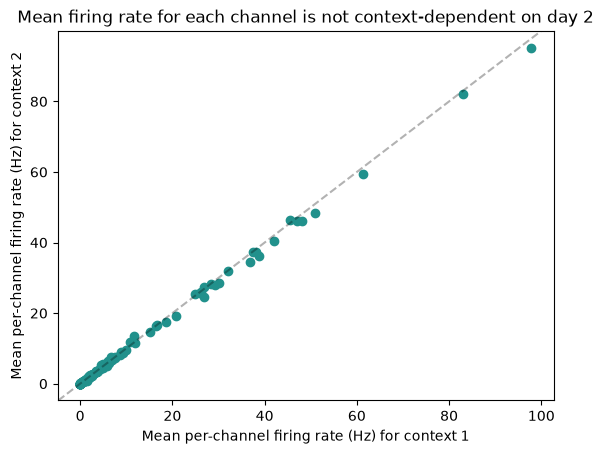

In [8]:
plt.scatter(context_tuning[:,0],context_tuning[:,1], color=cmap(0.5))
plt.axline((0, 0), slope=1, color='black', linestyle='--', alpha=.3)
plt.xlabel('Mean per-channel firing rate (Hz) for context 1')
plt.ylabel('Mean per-channel firing rate (Hz) for context 2')
plt.title('Mean firing rate for each channel is not context-dependent on day 2')
plt.savefig(f'{figure_path}/mean_contextdpdt_FR_day2.png')
plt.show()

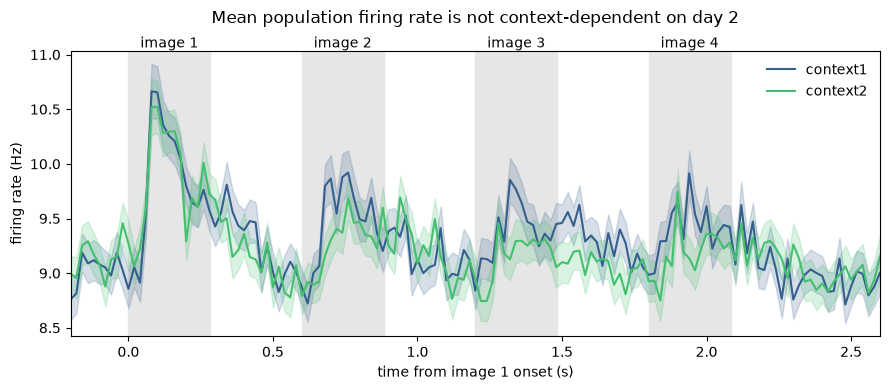

In [9]:
# population PSTH around sequences, split by context
bin_size = 0.02
window = (-0.2, 2.6)  # include data from 200ms before and after each sequence (4 images x 600ms = 2.4s per sequence)

first = imgs[imgs.pos == 1]
counts = spikes_a.count(bin_size)

fig, ax = plt.subplots(figsize=(9, 4))

for i, ctx in enumerate(["context1", "context2"]):
    onsets = nap.Ts(t=first[first.context == ctx].start)
    p = nap.compute_perievent(counts, onsets, window=window)    # (time, sequences, channels)
    rate = np.nanmean(np.asarray(p), axis=2) / bin_size         # population rate per sequence (Hz)
    m = rate.mean(axis=1)
    sem = rate.std(axis=1) / np.sqrt(rate.shape[1])
    ax.plot(p.t, m, label=ctx, color=colors[i])
    ax.fill_between(p.t, m - sem, m + sem, alpha=0.2, color=colors[i])

# shade each image's on-screen period (photodiode times, median relative to image 1)
for k in range(1, 5):
    on = np.median(imgs[imgs.pos == k].start - first.start)
    off = np.median(imgs[imgs.pos == k].end - first.start)
    ax.axvspan(on, off, color="0.9", zorder=0)
    ax.text((on + off) / 2, 1.0, f"image {k}", transform=ax.get_xaxis_transform(),
            ha="center", va="bottom")

ax.set(xlabel="time from image 1 onset (s)", ylabel="firing rate (Hz)", xlim=window)
ax.legend(frameon=False)
plt.title('Mean population firing rate is not context-dependent on day 2', pad=20)
plt.tight_layout()
plt.savefig(f'{figure_path}/population_contextdpdt_FR_day2')
plt.show()

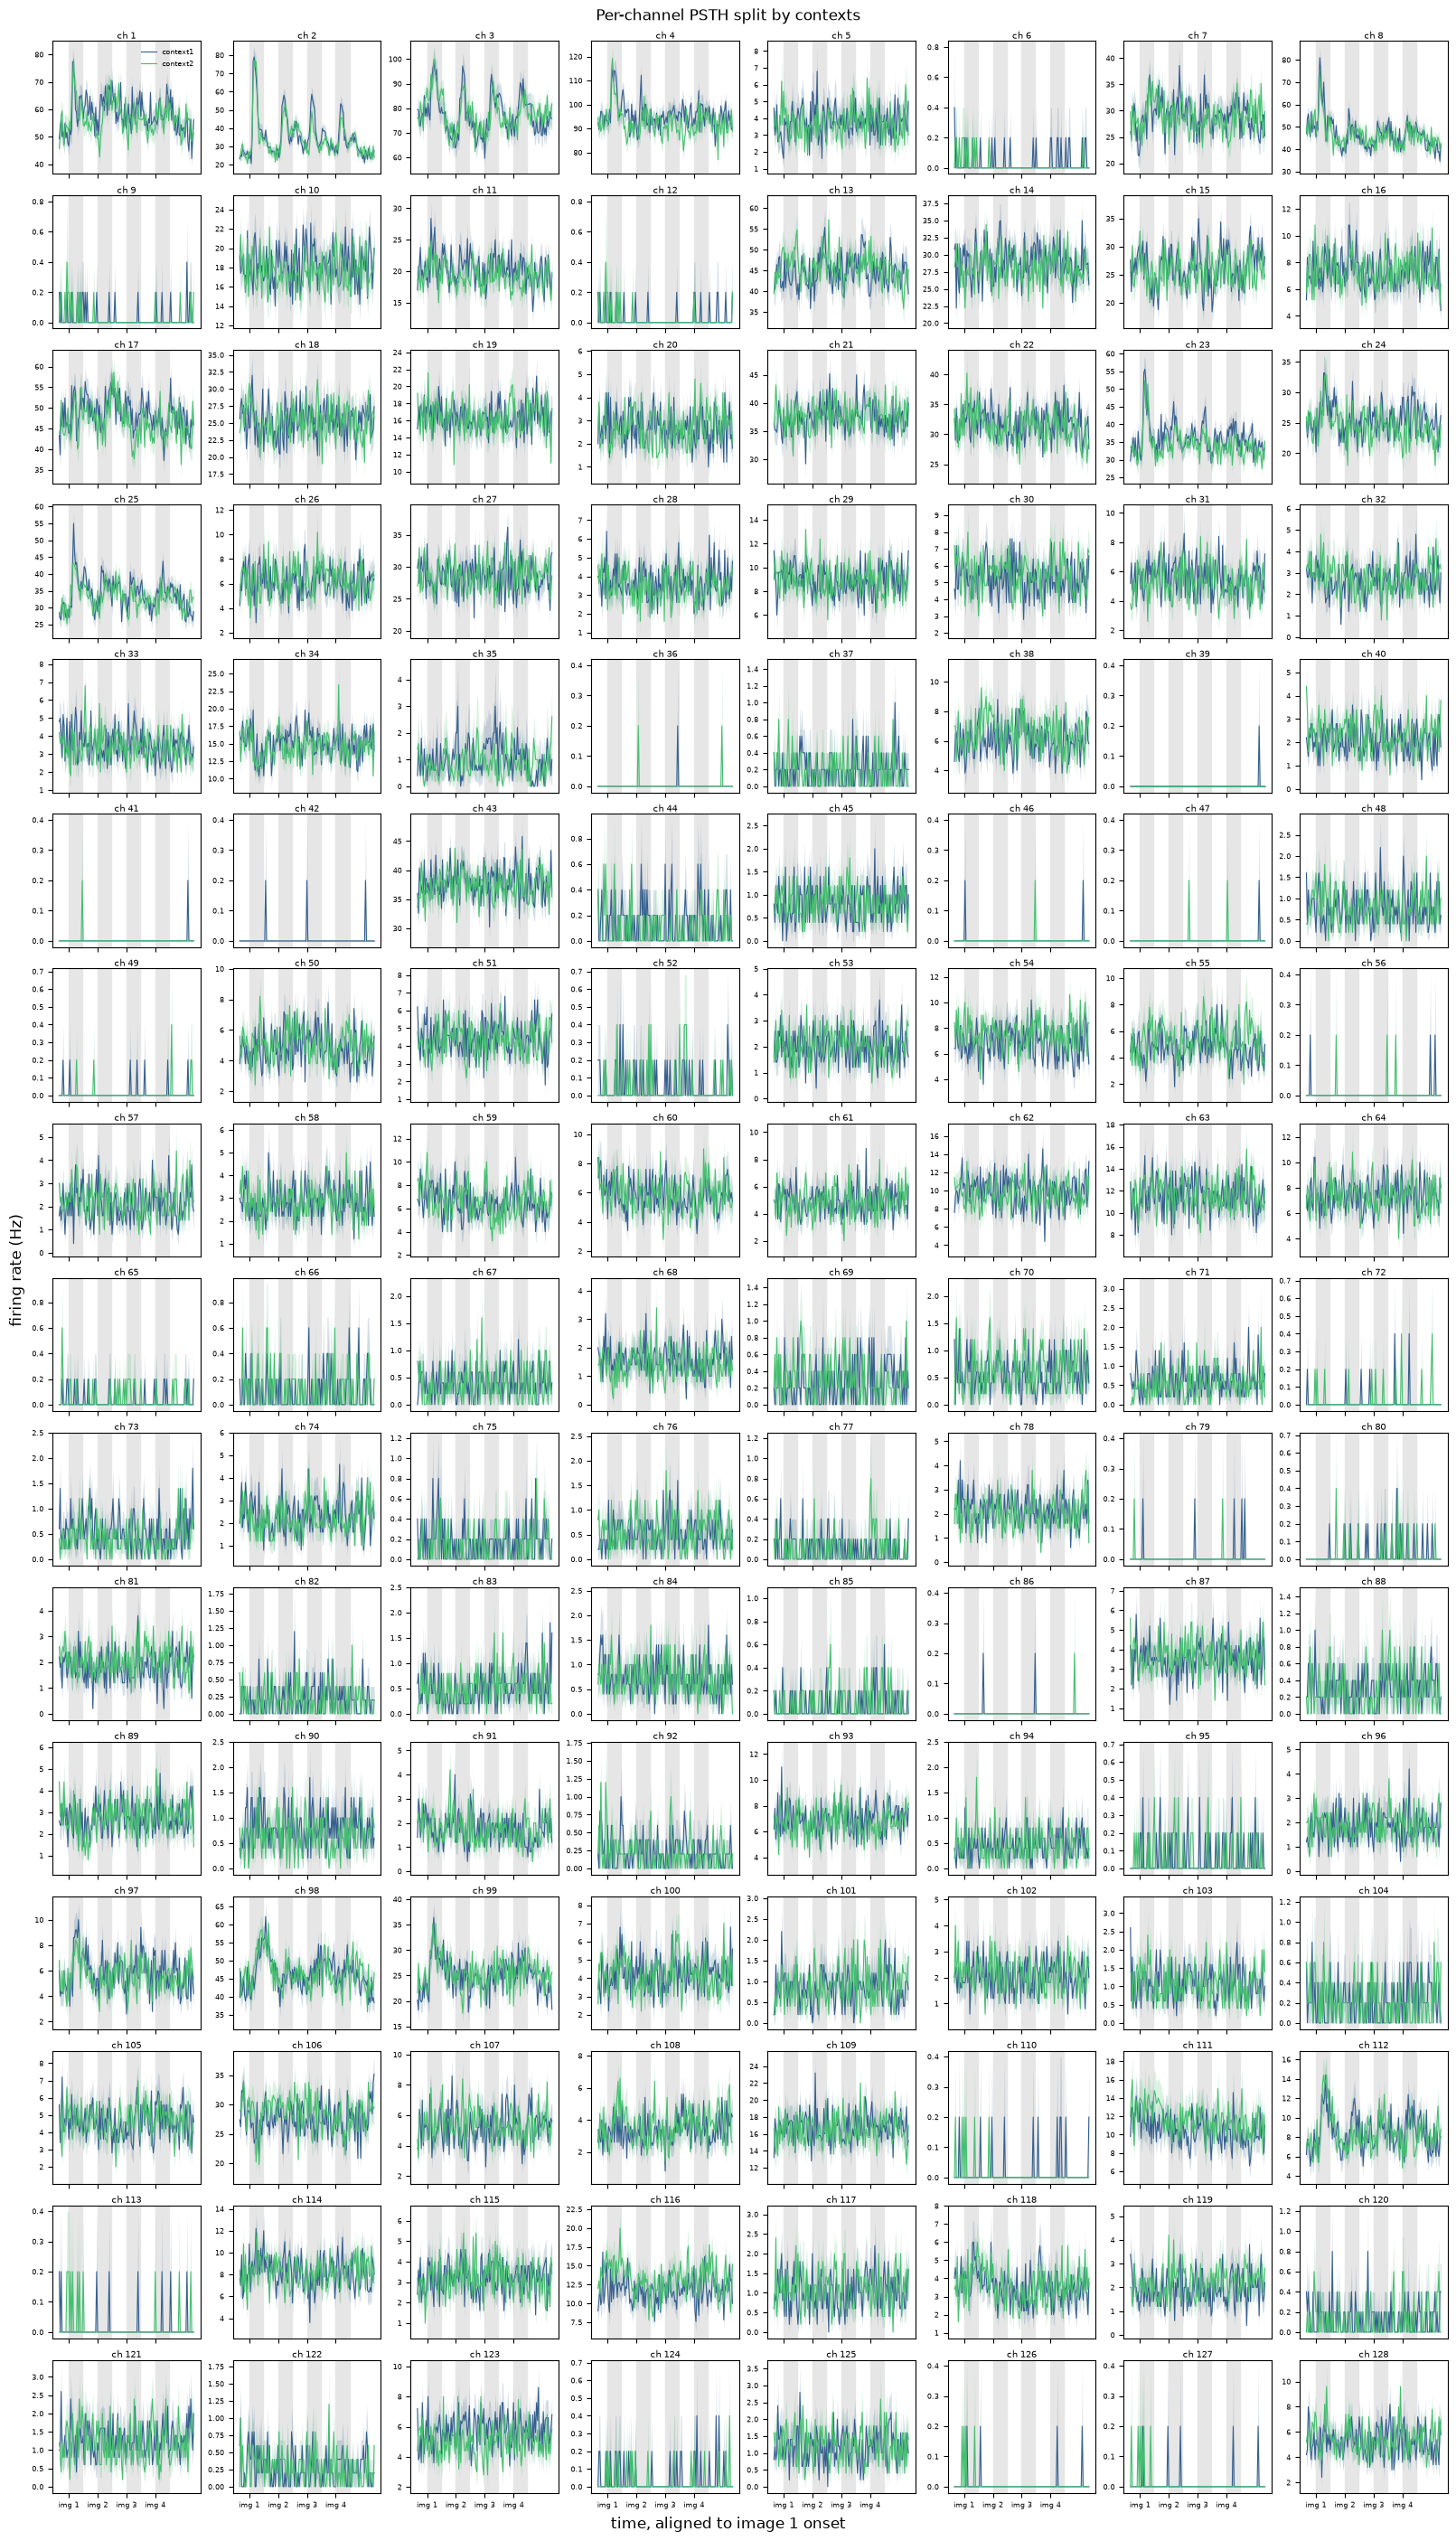

In [10]:
# rate[ctx]: (time, sequences, channels), in Hz — computed once, reused by every subplot
rate = {}
for ctx in contexts:
    p = nap.compute_perievent(counts, nap.Ts(t=first[first.context == ctx].start), window=window)
    rate[ctx] = np.asarray(p) / bin_size
t = p.t

img_on = [np.median(imgs[imgs.pos == k].start - first.start) for k in range(1, 5)]
img_off = [np.median(imgs[imgs.pos == k].end - first.start) for k in range(1, 5)]
ch_ids = np.asarray(spikes_a.channel_id)

fig, axs = plt.subplots(16, 8, figsize=(16, 28), sharex=True, constrained_layout=True)
for ch, ax in enumerate(axs.flat):
    for on, off in zip(img_on, img_off):
        ax.axvspan(on, off, color="0.9", zorder=0)
    for i, ctx in enumerate(contexts):
        r = rate[ctx][:, :, ch]
        m, sem = r.mean(axis=1), r.std(axis=1) / np.sqrt(r.shape[1])
        ax.plot(t, m, lw=0.8, label=ctx, color=colors[i])
        ax.fill_between(t, m - sem, m + sem, alpha=0.2, lw=0, color=colors[i])
    ax.set_title(f"ch {ch_ids[ch]}", fontsize=7, pad=2)
    ax.tick_params(labelsize=6)

axs[0, 0].legend(fontsize=6, frameon=False)
for ax in axs[-1]:
    ax.set_xticks(img_on, [f"img {k}" for k in range(1, 5)])
fig.supxlabel("time, aligned to image 1 onset")
fig.supylabel("firing rate (Hz)")
fig.suptitle('Per-channel PSTH split by contexts')
plt.savefig(f'{figure_path}/perchannel_contextdpdt_FR_day2')
plt.show()